# La historia para Medium: cómo la pandemia cambió la manera de escribir de la Universidad de Sonora

Este notebook reúne **todo el análisis del post** que está en `historia/post_medium.md`. Va sección por sección,
en el mismo orden que el post: primero calcula los números que se citan y después dibuja la gráfica que aparece en el post,
que se guarda en `historia/graficas/`.

| Sección del post | En este notebook | Gráfica |
|---|---|---|
| 1. Menos noticias, de golpe | 3 | `01_noticias_por_anio.png` |
| 2. Notas más largas, párrafos más cortos | 4 | `02_largo_y_parrafos.png` |
| 3. La pandemia llenó las notas de voces | 5 | `03_voces.png` |
| 4. 2025: las voces se apagan | 6 | `05_mes_a_mes.png`, `04_verbos.png` |
| 5. No cambió el equipo: cambió la línea editorial | 7 | `06_reporteros.png` |
| 6. La huella en las palabras pequeñas | 8 | `07_huella_de_estilo.png`, `08_lenguaje_incluyente.png` |

Al final (sección 9) hay una tabla con **todas las cifras que cita el post**, para revisarlas en un solo lugar.
El análisis más amplio, con más medidas, está en `05_como_se_hacen_las_noticias.ipynb`.

## 1. Librerías

In [1]:
import json
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import nltk
from nltk.corpus import stopwords

### El estilo de las gráficas

Estas funciones solo dan formato, para que todas las gráficas del post se vean igual:

- **Colores:** un fondo casi blanco, tintas grises para el texto y tres colores para las series (azul, naranja y verde),
  elegidos para que se distingan también con daltonismo.
- **Formato:** título y subtítulo arriba a la izquierda, solo rejilla horizontal, y la pandemia (2020–2021) y la nueva
  rectoría (2025–2026) sombreadas en gris.
- **guardar:** guarda la gráfica en `historia/graficas/` con la fuente al pie y la muestra aquí.

In [2]:
CARPETA = "historia/graficas"
FUENTE = "Fuente: 19,813 noticias de unison.mx, enero de 2015 a octubre de 2026."

SUPERFICIE = "#fcfcfb"   # fondo
TINTA = "#0b0b0b"        # texto principal
TINTA_2 = "#52514e"      # texto secundario
TENUE = "#898781"        # ejes y notas
REJILLA = "#e1e0d9"
BASE = "#c3c2b7"
BANDA = "#f0efec"        # sombreado de las etapas
AZUL = "#2a78d6"
NARANJA = "#eb6834"
AQUA = "#1baf7a"
AZUL_CLARO = "#86b6ef"

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 12,
    "axes.edgecolor": BASE,
    "axes.labelcolor": TINTA_2,
    "xtick.color": TENUE,
    "ytick.color": TENUE,
    "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2,
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "lines.linewidth": 2,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
})
os.makedirs(CARPETA, exist_ok=True)


def nueva_figura(titulo, subtitulo, ancho=11, alto=5.6, columnas=1, izquierda=0.07, espacio_arriba=1.25):
    """Figura con título y subtítulo arriba a la izquierda. Los márgenes van en pulgadas para que no cambien con el alto."""
    fig, ejes = plt.subplots(1, columnas, figsize=(ancho, alto))
    fig.subplots_adjust(top=1 - espacio_arriba / alto, bottom=0.75 / alto, left=izquierda, right=0.96, wspace=0.25)
    fig.text(0.07, 1 - 0.25 / alto, titulo, fontsize=17, fontweight="bold", color=TINTA, ha="left", va="top")
    fig.text(0.07, 1 - 0.65 / alto, subtitulo, fontsize=12, color=TINTA_2, ha="left", va="top")
    return fig, ejes


def estilo_ejes(eje, rejilla_y=True):
    """Quita los bordes, deja solo la línea de base y una rejilla horizontal suave."""
    for lado in ["top", "right", "left"]:
        eje.spines[lado].set_visible(False)
    eje.spines["bottom"].set_color(BASE)
    eje.tick_params(length=0)
    if rejilla_y:
        eje.grid(axis="y", color=REJILLA, linewidth=1)
        eje.set_axisbelow(True)


def bandas(eje):
    """Sombrea la pandemia (2020–2021) y la nueva rectoría (2025–2026) en una gráfica por año."""
    eje.axvspan(2019.5, 2021.5, color=BANDA, zorder=0)
    eje.axvspan(2024.5, 2026.5, color=BANDA, zorder=0)
    arriba = eje.get_ylim()[1]
    eje.text(2020.5, arriba, "Pandemia", ha="center", va="bottom", fontsize=10, color=TINTA_2)
    eje.text(2025.5, arriba, "Nueva rectoría", ha="center", va="bottom", fontsize=10, color=TINTA_2)


def etiqueta(eje, x, y, texto, dx=0, dy=8, ha="center"):
    """Escribe un valor junto a un punto de la gráfica."""
    eje.annotate(texto, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=11, color=TINTA)


def guardar(fig, nombre, nota=""):
    """Agrega la fuente al pie, guarda la gráfica en historia/graficas/ y la muestra."""
    fig.text(0.07, 0.2 / fig.get_figheight(), (nota + "  " if nota else "") + FUENTE, fontsize=9, color=TENUE, ha="left")
    fig.savefig(os.path.join(CARPETA, nombre), dpi=200, facecolor=SUPERFICIE)
    plt.show()

## 2. Los datos

Cargamos las noticias como en los notebooks anteriores y preparamos las medidas que usa el post:

- **autor** con las variantes de un mismo nombre unificadas, y **firma**: el autor o, antes de 2018, las iniciales al final del texto.
- **porcentaje_en_citas:** qué parte de las palabras de la nota está entre comillas.
- **titular_con_cita:** si el titular termina con dos puntos y quien habla (*"...: rectora"*); vale 100 o 0 para promediar en porcentaje.
- **palabras_por_parrafo.**

In [3]:
registros = []
with open("data/raw/noticias_unison.jsonl", encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

noticias = pd.DataFrame(registros)
noticias = noticias[noticias["estado"] == "ok"].drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)
noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias["n_parrafos"] = noticias["n_parrafos"].astype(int)
noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)

anios = sorted(noticias["anio"].unique())
print("Noticias:", len(noticias), "| de", noticias["fecha"].min().date(), "a", noticias["fecha"].max().date())

Noticias: 19813 | de 2015-01-02 a 2026-10-29


In [4]:
VARIANTES_AUTOR = {
    "Beatriz Angélica Espinoza": "Beatriz Espinoza", "Beatriz Angélica Espinoza Sotelo": "Beatriz Espinoza",
    "Haydeé Gaxiola": "Haydee Gaxiola", "Luz Haydee Gaxiola Cabrera": "Haydee Gaxiola",
    "Luz Haydeé Gaxiola Cabrera": "Haydee Gaxiola",
    "Paula Trespalacios": "Paula Trespalacios Argain", "Paula Trespalcios Argain": "Paula Trespalacios Argain",
    "Lin Mendívil Alvarado": "Lin Mendivil Alvarado",
    "Denisse López Martínez": "Denice López Martínez", "Denise López Martínez": "Denice López Martínez",
    "Elias Quijada": "Elías Quijada", "Elías Quijada López": "Elías Quijada",
    "Jesús Albero Rubio": "Jesús Alberto Rubio",
}
noticias["autor"] = noticias["autor"].str.replace(r"^Por:? ", "", regex=True).str.strip().replace(VARIANTES_AUTOR)

iniciales = noticias["texto"].str.strip().str.extract(r"\(([A-ZÁÉÍÓÚÑ]{2,6})\)\.?$")[0]   # "(JAR)" al final
noticias["firma"] = noticias["autor"].fillna(iniciales)

citas = noticias["texto"].str.findall(r"[“\"]([^”\"]{3,})[”\"]")              # cada cita, sin las comillas
noticias["tiene_cita"] = citas.str.len() > 0
noticias["porcentaje_en_citas"] = citas.apply(lambda lista: sum(len(cita.split()) for cita in lista)) / noticias["n_palabras"] * 100
noticias["titular_con_cita"] = noticias["titulo"].str.contains(r":\s*\S") * 100
noticias["palabras_por_parrafo"] = noticias["n_palabras"] / noticias["n_parrafos"]

noticias[["fecha", "firma", "titulo", "porcentaje_en_citas", "titular_con_cita"]].tail()

,fecha,firma,titulo,porcentaje_en_citas,titular_con_cita
19808,2026-10-29,Beatriz Espinoza,Inauguran Jornadas de Administración 2026 por ...,1.555556,0
19809,2026-10-29,Elías Quijada,Analiza académico de la Unison protección jurí...,13.333333,0
19810,2026-10-29,Beatriz Espinoza,Promueven bienestar emocional y prevención del...,8.108108,0
19811,2026-10-29,Paula Trespalacios Argain,Preservan en un libro la historia de los mural...,27.469880,0
19812,2026-10-29,Paula Trespalacios Argain,Celebra la Unison la edición 25 de su tradicio...,0.000000,0


## 3. Menos noticias, de golpe (sección 1 del post)

### 3.1 Noticias por año

2026 va incompleto, así que también comparamos todos los años **hasta el mismo día del año** que la última nota.

In [5]:
ultima_fecha = noticias["fecha"].max()
hasta_mismo_dia = noticias[noticias["fecha"].dt.day_of_year <= ultima_fecha.day_of_year]

produccion = pd.DataFrame({
    "noticias": noticias["anio"].value_counts().sort_index(),
    "hasta el mismo día": hasta_mismo_dia["anio"].value_counts().sort_index(),
})
caida_2020 = (produccion.loc[2020, "hasta el mismo día"] / produccion.loc[2019, "hasta el mismo día"] - 1) * 100
caida_2026 = (produccion.loc[2026, "hasta el mismo día"] / produccion.loc[2025, "hasta el mismo día"] - 1) * 100

print(f"2020 contra 2019, a la misma fecha: {caida_2020:.0f}%")
print(f"2026 contra 2025, a la misma fecha: {caida_2026:.0f}%")
produccion

2020 contra 2019, a la misma fecha: -48%
2026 contra 2025, a la misma fecha: -14%


,noticias,hasta el mismo día
anio,,
2015,2377,1902
2016,2337,1898
2017,2052,1658
2018,2058,1697
2019,1705,1333
2020,946,697
2021,1356,1058
2022,1613,1313
2023,1650,1350


### 3.2 Cuándo se publica y quién escribe

- **% de días con noticias:** cuántos días del año tuvieron al menos una nota (en 2026, sobre los días transcurridos).
- **% en fin de semana:** qué parte de las notas sale en sábado o domingo.
- **Firmas con 20+ notas** (el equipo) y qué parte de las notas firmadas escriben las tres principales.

In [6]:
dias_del_anio = pd.Series({anio: 366 if anio % 4 == 0 else 365 for anio in anios})
dias_del_anio[ultima_fecha.year] = ultima_fecha.day_of_year

equipo = {}
for anio, notas_del_anio in noticias.groupby("anio"):
    por_firma = notas_del_anio["firma"].value_counts()
    equipo[anio] = {
        "% de días con noticias": notas_del_anio["fecha"].nunique() / dias_del_anio[anio] * 100,
        "% en fin de semana": (notas_del_anio["fecha"].dt.day_of_week >= 5).mean() * 100,
        "firmas con 20+ notas": (por_firma >= 20).sum(),
        "% de las 3 principales": por_firma.head(3).sum() / por_firma.sum() * 100,
    }

equipo = pd.DataFrame(equipo).T
equipo.round(1)

,% de días con noticias,% en fin de semana,firmas con 20+ notas,% de las 3 principales
2015,77.8,2.0,9.0,67.9
2016,85.5,5.4,9.0,60.7
2017,84.9,5.1,8.0,72.7
2018,82.5,5.4,12.0,37.7
2019,76.7,3.5,8.0,63.7
2020,67.2,7.1,7.0,66.2
2021,80.5,7.5,9.0,59.3
2022,76.2,2.6,8.0,68.7
2023,80.3,4.5,7.0,63.5
2024,77.6,3.6,6.0,76.9


*En 2018 conviven las iniciales y los nombres completos, así que ese año el equipo parece más grande de lo que fue.*

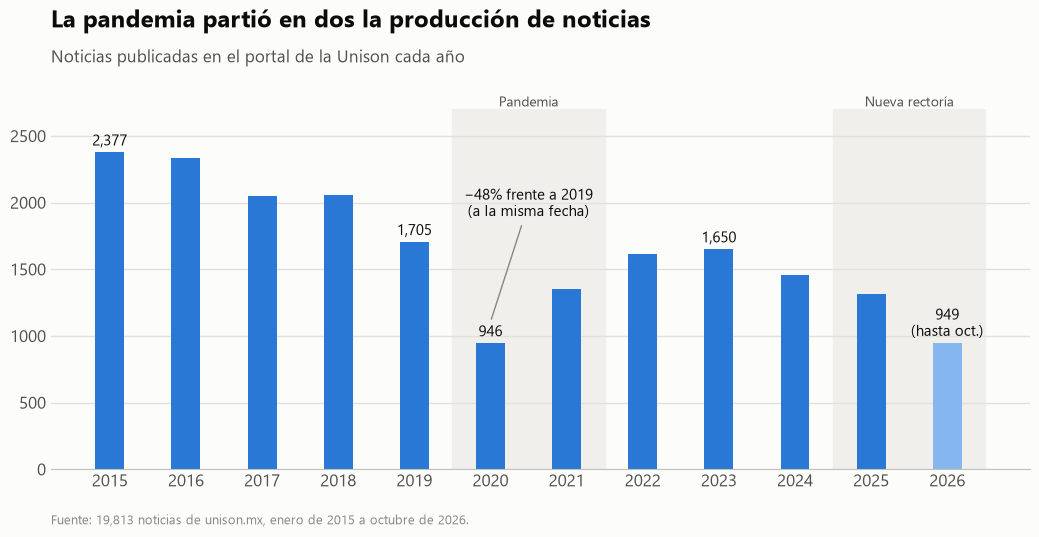

In [7]:
por_anio = produccion["noticias"]

fig, eje = nueva_figura("La pandemia partió en dos la producción de noticias",
                        "Noticias publicadas en el portal de la Unison cada año")
colores = [AZUL_CLARO if anio == ultima_fecha.year else AZUL for anio in anios]   # 2026, incompleto, más claro
eje.bar(por_anio.index, por_anio.values, width=0.38, color=colores, zorder=2)
estilo_ejes(eje)
eje.set_ylim(0, 2700)
eje.set_xticks(anios)
bandas(eje)
for anio in [2015, 2019, 2020, 2023]:
    etiqueta(eje, anio, por_anio[anio], f"{por_anio[anio]:,}", dy=5)
etiqueta(eje, ultima_fecha.year, por_anio[ultima_fecha.year], f"{por_anio[ultima_fecha.year]:,}\n(hasta oct.)", dy=5)

texto_caida = f"{caida_2020:.0f}% frente a 2019\n(a la misma fecha)".replace("-", "−")
eje.annotate(texto_caida, (2020, por_anio[2020] + 160), xytext=(2020.5, 1900), ha="center", fontsize=11, color=TINTA,
             arrowprops={"arrowstyle": "-", "color": TENUE, "linewidth": 1})
guardar(fig, "01_noticias_por_anio.png")

## 4. Notas más largas, párrafos más cortos (sección 2 del post)

Usamos la **mediana** de cada año: el valor de la nota típica, que no se mueve por unas cuantas notas muy largas.

In [8]:
medianas = noticias.groupby("anio")[["n_palabras", "n_parrafos", "palabras_por_parrafo"]].median()
medianas.columns = ["palabras por noticia", "párrafos por noticia", "palabras por párrafo"]
medianas.round(1)

,palabras por noticia,párrafos por noticia,palabras por párrafo
anio,,,
2015,371.0,8.0,46.6
2016,382.0,8.0,46.0
2017,375.0,8.0,46.2
2018,382.5,8.0,45.0
2019,435.0,9.0,47.8
2020,518.0,10.0,50.1
2021,587.0,12.0,47.4
2022,537.0,13.0,42.6
2023,478.0,12.0,39.9


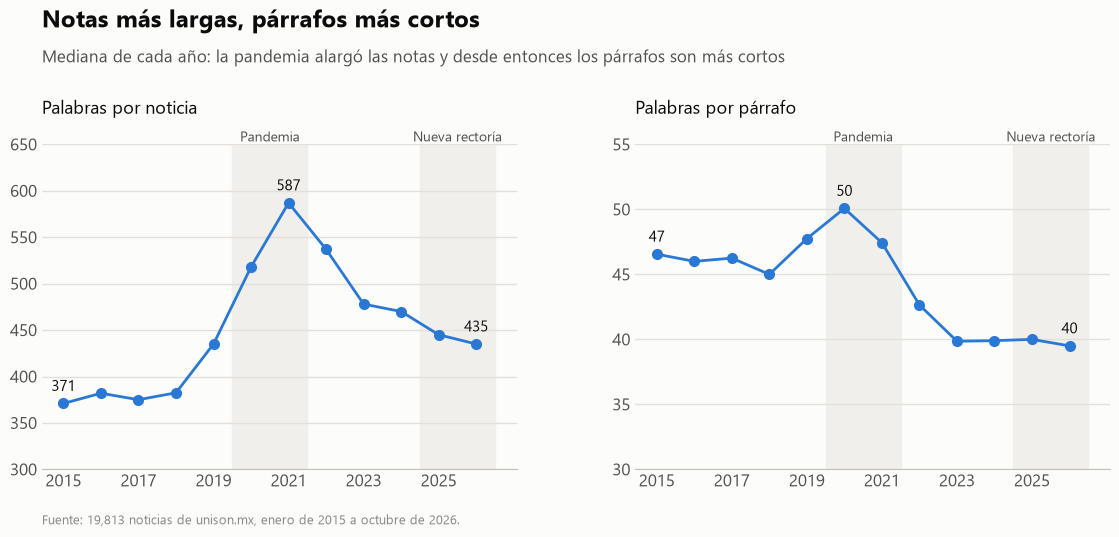

In [9]:
fig, (izquierda, derecha) = nueva_figura("Notas más largas, párrafos más cortos",
                                         "Mediana de cada año: la pandemia alargó las notas y desde entonces los párrafos son más cortos",
                                         ancho=12, columnas=2, espacio_arriba=1.6)

for eje, columna, rango in [(izquierda, "palabras por noticia", (300, 650)), (derecha, "palabras por párrafo", (30, 55))]:
    serie = medianas[columna]
    eje.plot(serie.index, serie.values, color=AZUL, marker="o", markersize=7, zorder=3)
    estilo_ejes(eje)
    eje.set_ylim(*rango)
    eje.set_xticks(anios[::2])
    eje.set_title(columna.capitalize(), loc="left", fontsize=13, color=TINTA, pad=22)
    bandas(eje)
    for anio in [anios[0], serie.idxmax(), anios[-1]]:       # primer año, el más alto y el último
        etiqueta(eje, anio, serie[anio], f"{serie[anio]:.0f}", dy=9)

guardar(fig, "02_largo_y_parrafos.png")

## 5. La pandemia llenó las notas de voces (sección 3 del post)

Promedio de cada año: qué parte del texto está entre comillas, qué parte de las notas tiene alguna cita y qué parte de los
titulares cita a alguien.

In [10]:
voces = noticias.groupby("anio").agg(
    texto_entre_comillas=("porcentaje_en_citas", "mean"),
    notas_con_alguna_cita=("tiene_cita", "mean"),
    titulares_con_cita=("titular_con_cita", "mean"),
)
voces["notas_con_alguna_cita"] = voces["notas_con_alguna_cita"] * 100
voces.round(1)

,texto_entre_comillas,notas_con_alguna_cita,titulares_con_cita
anio,,,
2015,14.7,86.7,8.6
2016,14.3,80.1,10.6
2017,13.2,70.4,12.0
2018,13.2,69.8,10.6
2019,15.5,76.9,15.6
2020,17.4,79.2,13.1
2021,20.6,86.4,17.6
2022,24.6,92.6,16.1
2023,22.3,87.9,12.5


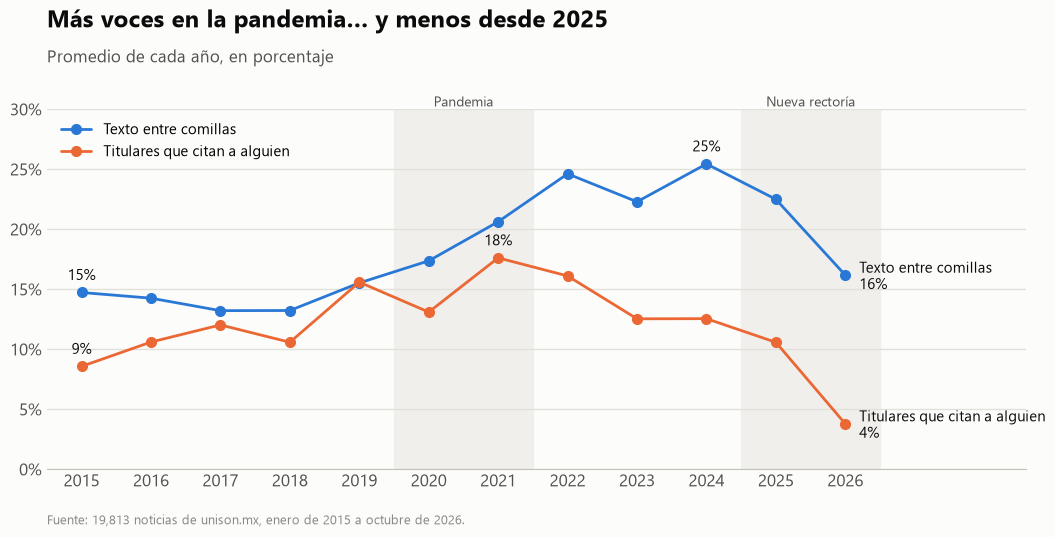

In [11]:
fig, eje = nueva_figura("Más voces en la pandemia… y menos desde 2025", "Promedio de cada año, en porcentaje")

for columna, nombre, color in [("texto_entre_comillas", "Texto entre comillas", AZUL),
                               ("titulares_con_cita", "Titulares que citan a alguien", NARANJA)]:
    serie = voces[columna]
    eje.plot(serie.index, serie.values, color=color, marker="o", markersize=7, label=nombre, zorder=3)
    etiqueta(eje, anios[-1], serie[anios[-1]], f"{nombre}\n{serie[anios[-1]]:.0f}%", dx=10, dy=-10, ha="left")
    etiqueta(eje, serie.idxmax(), serie.max(), f"{serie.max():.0f}%", dy=9)
    etiqueta(eje, anios[0], serie[anios[0]], f"{serie[anios[0]]:.0f}%", dy=9)

estilo_ejes(eje)
eje.set_ylim(0, 30)
eje.set_xlim(2014.5, 2028.6)          # espacio a la derecha para las etiquetas
eje.set_xticks(anios)
eje.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "03_voces.png")

## 6. 2025: las voces se apagan (sección 4 del post)

### 6.1 Mes por mes

El 16 de junio de 2025 asumió la nueva rectora (según el propio portal: *"Asume Dena María Camarena Gómez la Rectoría
de la Universidad de Sonora"*). Vemos las citas mes por mes desde 2024. Como algunos meses tienen pocas notas (julio, por
vacaciones), en la gráfica usamos un **promedio móvil de 3 meses**: cada punto es el promedio de ese mes y sus dos vecinos.

In [12]:
recientes = noticias[noticias["fecha"] >= "2024-01-01"]
por_mes = recientes.groupby(recientes["fecha"].dt.to_period("M").dt.to_timestamp()).agg(
    notas=("id", "count"),
    texto_entre_comillas=("porcentaje_en_citas", "mean"),
    titulares_con_cita=("titular_con_cita", "mean"),
)
por_mes.round(1)

,notas,texto_entre_comillas,titulares_con_cita
fecha,,,
2024-01-01,112,27.5,16.1
2024-02-01,116,26.3,20.7
2024-03-01,133,23.6,9.8
2024-04-01,128,25.5,14.8
2024-05-01,92,23.7,15.2
2024-06-01,124,22.4,8.9
2024-07-01,47,30.9,17.0
2024-08-01,122,24.4,8.2
2024-09-01,142,25.0,12.7


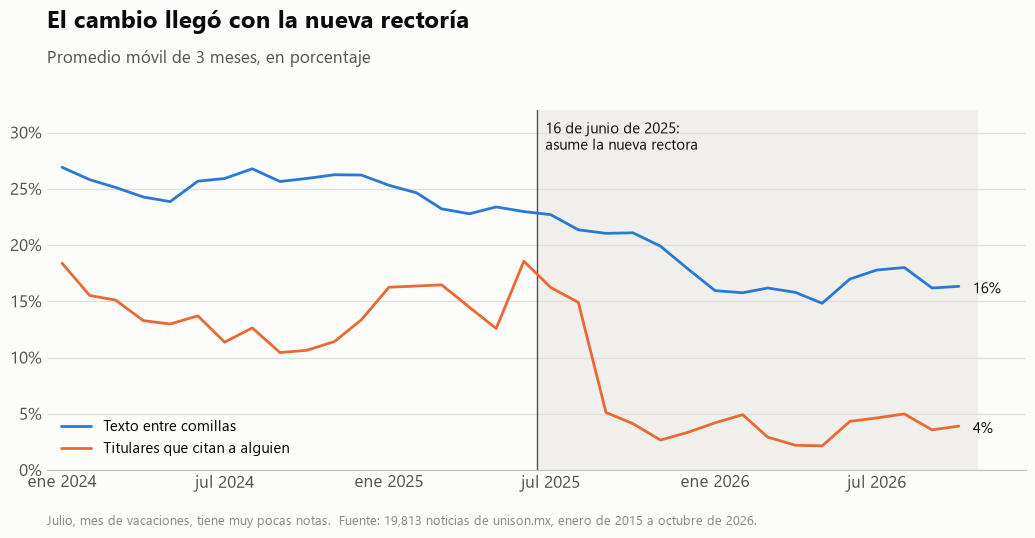

In [13]:
suavizado = por_mes[["texto_entre_comillas", "titulares_con_cita"]].rolling(3, center=True, min_periods=2).mean()
cambio_de_rectoria = pd.Timestamp("2025-06-16")

fig, eje = nueva_figura("El cambio llegó con la nueva rectoría", "Promedio móvil de 3 meses, en porcentaje")
eje.axvspan(cambio_de_rectoria, por_mes.index.max() + pd.Timedelta(days=20), color=BANDA, zorder=0)
for columna, nombre, color in [("texto_entre_comillas", "Texto entre comillas", AZUL),
                               ("titulares_con_cita", "Titulares que citan a alguien", NARANJA)]:
    serie = suavizado[columna]
    eje.plot(serie.index, serie.values, color=color, label=nombre, zorder=3)
    eje.annotate(f"{serie.iloc[-1]:.0f}%", (serie.index[-1], serie.iloc[-1]), xytext=(10, -5),
                 textcoords="offset points", fontsize=11, color=TINTA, ha="left")
eje.axvline(cambio_de_rectoria, color=TINTA_2, linewidth=1)
eje.text(cambio_de_rectoria, 31, "  16 de junio de 2025:\n  asume la nueva rectora", fontsize=11, color=TINTA, va="top")

estilo_ejes(eje)
eje.set_ylim(0, 32)
eje.set_xlim(pd.Timestamp("2023-12-15"), pd.Timestamp("2026-12-15"))
marcas = pd.date_range("2024-01-01", "2026-07-01", freq="6MS")          # enero y julio de cada año
eje.set_xticks(marcas, [f"{'ene' if fecha.month == 1 else 'jul'} {fecha.year}" for fecha in marcas])
eje.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")
eje.legend(loc="lower left", frameon=False, fontsize=11)
guardar(fig, "05_mes_a_mes.png", nota="Julio, mes de vacaciones, tiene muy pocas notas.")

### 6.2 Los verbos con que se cita

Contamos cada verbo de cita por cada 10,000 palabras, antes de la pandemia (2015–2019) y en la nueva etapa (2025–2026).

In [14]:
VERBOS = ["dijo", "indicó", "afirmó", "sostuvo", "apuntó", "comentó",
          "destacó", "explicó", "compartió", "detalló", "precisó", "subrayó"]

palabras_por_noticia = noticias["texto"].str.lower().str.findall(r"[a-záéíóúüñ]+")


def verbos_por_10mil(filtro):
    """Usos de cada verbo por cada 10,000 palabras en las noticias que cumplen el filtro."""
    conteo = Counter()
    total = 0
    for palabras in palabras_por_noticia[filtro]:
        conteo.update(palabra for palabra in palabras if palabra in VERBOS)
        total += len(palabras)
    return pd.Series({verbo: conteo[verbo] / total * 10000 for verbo in VERBOS})


verbos = pd.DataFrame({
    "2015–2019": verbos_por_10mil(noticias["anio"] <= 2019),
    "2025–2026": verbos_por_10mil(noticias["anio"] >= 2025),
})
verbos["cambio"] = verbos["2025–2026"] - verbos["2015–2019"]
verbos = verbos.sort_values("cambio")
verbos.round(1)

,2015–2019,2025–2026,cambio
dijo,16.8,8.3,-8.4
indicó,8.3,5.1,-3.2
apuntó,2.8,1.0,-1.8
comentó,6.3,4.7,-1.6
sostuvo,2.1,0.6,-1.5
afirmó,2.7,1.3,-1.3
subrayó,2.3,3.9,1.5
precisó,2.4,5.3,2.9
detalló,0.9,4.5,3.6
compartió,1.0,4.7,3.7


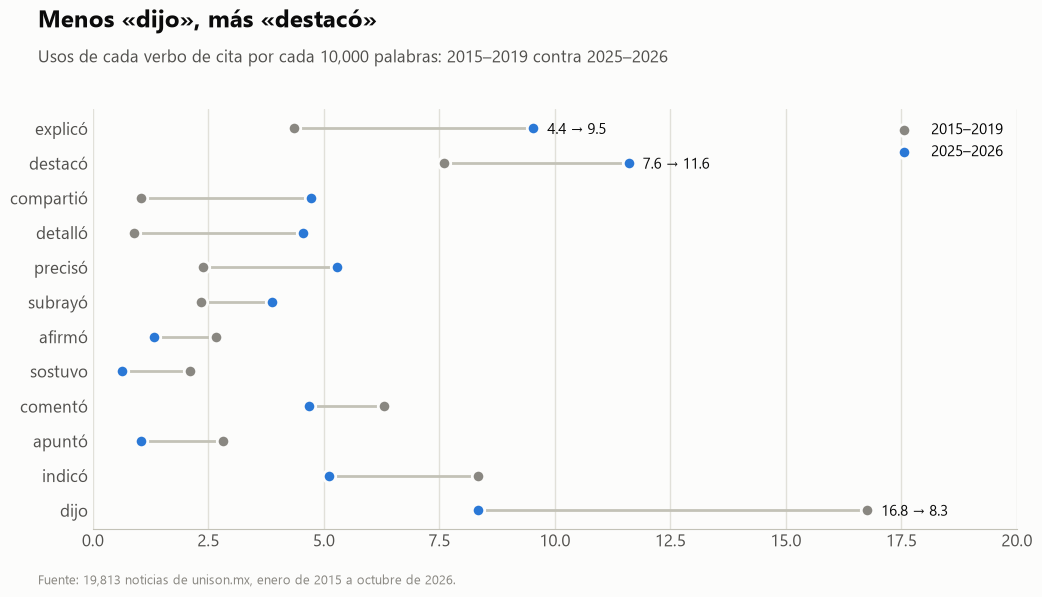

In [15]:
antes, despues = verbos["2015–2019"], verbos["2025–2026"]
orden = verbos.index

fig, eje = nueva_figura("Menos «dijo», más «destacó»",
                        "Usos de cada verbo de cita por cada 10,000 palabras: 2015–2019 contra 2025–2026",
                        alto=6.2, izquierda=0.12)
for posicion, verbo in enumerate(orden):                         # la línea que une los dos periodos
    eje.plot([antes[verbo], despues[verbo]], [posicion, posicion], color=BASE, linewidth=2, zorder=1)
eje.scatter(antes, range(len(orden)), s=80, color=TENUE, edgecolor=SUPERFICIE, linewidth=2, zorder=2, label="2015–2019")
eje.scatter(despues, range(len(orden)), s=80, color=AZUL, edgecolor=SUPERFICIE, linewidth=2, zorder=3, label="2025–2026")
eje.set_yticks(range(len(orden)), orden, fontsize=12)

estilo_ejes(eje, rejilla_y=False)
eje.grid(axis="x", color=REJILLA, linewidth=1)
eje.set_axisbelow(True)
eje.set_xlim(0, 20)
for verbo in ["dijo", "destacó", "explicó"]:
    eje.annotate(f"{antes[verbo]:.1f} → {despues[verbo]:.1f}", (max(antes[verbo], despues[verbo]), list(orden).index(verbo)),
                 xytext=(10, -4), textcoords="offset points", fontsize=11, color=TINTA)
eje.legend(loc="upper right", frameon=False, fontsize=11)
guardar(fig, "04_verbos.png")

## 7. No cambió el equipo: cambió la línea editorial (sección 5 del post)

Comparamos a las tres firmas que escriben la mayoría de las notas **consigo mismas** a lo largo de los años
(solo años con al menos 30 notas suyas). En el post no usamos sus nombres: lo que importa es que son las mismas personas.

In [16]:
PERIODISTAS = {"Paula Trespalacios Argain": "Periodista A", "Beatriz Espinoza": "Periodista B", "Elías Quijada": "Periodista C"}

noticias["dijo_por_10mil"] = noticias["texto"].str.count(r"\bdijo\b") / noticias["n_palabras"] * 10000
de_periodistas = noticias[noticias["autor"].isin(PERIODISTAS)].copy()
de_periodistas["periodista"] = de_periodistas["autor"].map(PERIODISTAS)

por_periodista = de_periodistas.groupby(["periodista", "anio"]).agg(
    notas=("id", "count"),
    texto_entre_comillas=("porcentaje_en_citas", "mean"),
    titulares_con_cita=("titular_con_cita", "mean"),
    dijo_por_10mil=("dijo_por_10mil", "mean"),
)
por_periodista = por_periodista[por_periodista["notas"] >= 30]
por_periodista.loc[(slice(None), [2024, 2025, 2026]), :].round(1)

notas  texto_entre_comillas  titulares_con_cita  \
periodista   anio                                                    
Periodista A 2024    419                  34.2                 9.8   
             2025    350                  32.1                 6.6   
             2026    235                  25.3                 1.3   
Periodista B 2024    390                  20.5                11.8   
             2025    362                  16.7                10.2   
             2026    240                  11.9                 4.6   
Periodista C 2024    279                  18.0                22.6   
             2025    251                  15.4                19.1   
             2026    174                   8.6                 7.5   

                   dijo_por_10mil  
periodista   anio                  
Periodista A 2024             8.4  
             2025             5.2  
             2026             3.6  
Periodista B 2024            17.7  
             2025            13.8  
             2026             8.2  
Periodista C 2024            12.2  
             2025             9.0  
             2026             4.9

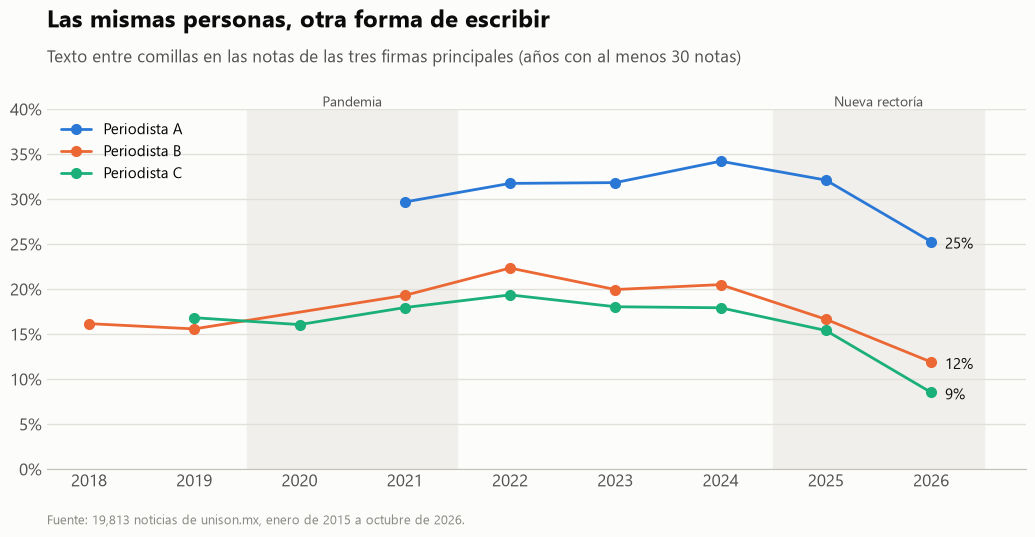

In [17]:
fig, eje = nueva_figura("Las mismas personas, otra forma de escribir",
                        "Texto entre comillas en las notas de las tres firmas principales (años con al menos 30 notas)")

for (periodista, color) in zip(["Periodista A", "Periodista B", "Periodista C"], [AZUL, NARANJA, AQUA]):
    serie = por_periodista.loc[periodista, "texto_entre_comillas"]
    eje.plot(serie.index, serie.values, color=color, marker="o", markersize=7, label=periodista, zorder=3)
    eje.annotate(f"{serie.iloc[-1]:.0f}%", (serie.index[-1], serie.iloc[-1]),
                 xytext=(10, -5), textcoords="offset points", fontsize=11, color=TINTA, ha="left")

estilo_ejes(eje)
eje.set_ylim(0, 40)
eje.set_xlim(2017.6, 2026.9)
eje.set_xticks(range(2018, 2027))
eje.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "06_reporteros.png")

## 8. La huella en las palabras pequeñas (sección 6 del post)

### 8.1 Delta de Burrows

Para el estilo importan justo las palabras que se quitan al analizar temas (*de, la, que, los...*): cada quien las usa en
proporciones distintas sin darse cuenta. El método clásico para comparar estilos es la **Delta de Burrows**:

1. Tomamos las 60 *stopwords* más frecuentes del corpus.
2. Para cada año calculamos cuántas veces aparece cada una por cada 1,000 palabras.
3. Las convertimos en **puntajes z** (cuánto se aleja cada año del promedio, en desviaciones estándar).
4. La **distancia** entre dos años es el promedio de las diferencias (en valor absoluto) de sus puntajes: 0 = mismo estilo.

In [18]:
nltk.download("stopwords", quiet=True)
stopwords_es = set(stopwords.words("spanish"))

total_funcionales = Counter()
for palabras in palabras_por_noticia:
    total_funcionales.update(palabra for palabra in palabras if palabra in stopwords_es)
funcionales = [palabra for palabra, veces in total_funcionales.most_common(60)]

frecuencias = {}
for anio in anios:
    conteo = Counter()
    total = 0
    for palabras in palabras_por_noticia[noticias["anio"] == anio]:
        conteo.update(palabra for palabra in palabras if palabra in funcionales)
        total += len(palabras)
    frecuencias[anio] = {palabra: conteo[palabra] / total * 1000 for palabra in funcionales}

frecuencias = pd.DataFrame(frecuencias)                     # filas: palabras, columnas: años
puntajes_z = frecuencias.sub(frecuencias.mean(axis=1), axis=0).div(frecuencias.std(axis=1), axis=0)
delta = pd.DataFrame({a: {b: (puntajes_z[a] - puntajes_z[b]).abs().mean() for b in anios} for a in anios})
delta.round(2)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
2015,0.00,0.39,0.46,0.62,0.76,1.00,1.07,1.32,1.06,1.37,1.01,1.77
2016,0.39,0.00,0.43,0.60,0.67,0.83,0.97,1.16,0.92,1.30,1.04,1.89
2017,0.46,0.43,0.00,0.36,0.63,0.89,1.01,1.20,0.96,1.35,1.02,1.82
2018,0.62,0.60,0.36,0.00,0.60,0.92,1.09,1.34,1.12,1.52,1.18,1.88
2019,0.76,0.67,0.63,0.60,0.00,0.69,0.90,1.16,0.96,1.34,1.07,1.94
2020,1.00,0.83,0.89,0.92,0.69,0.00,0.54,0.93,0.91,1.23,1.00,1.99
2021,1.07,0.97,1.01,1.09,0.90,0.54,0.00,0.74,0.80,1.13,1.02,2.08
2022,1.32,1.16,1.20,1.34,1.16,0.93,0.74,0.00,0.58,0.75,1.17,2.48
2023,1.06,0.92,0.96,1.12,0.96,0.91,0.80,0.58,0.00,0.71,1.01,2.32
2024,1.37,1.30,1.35,1.52,1.34,1.23,1.13,0.75,0.71,0.00,1.09,2.53


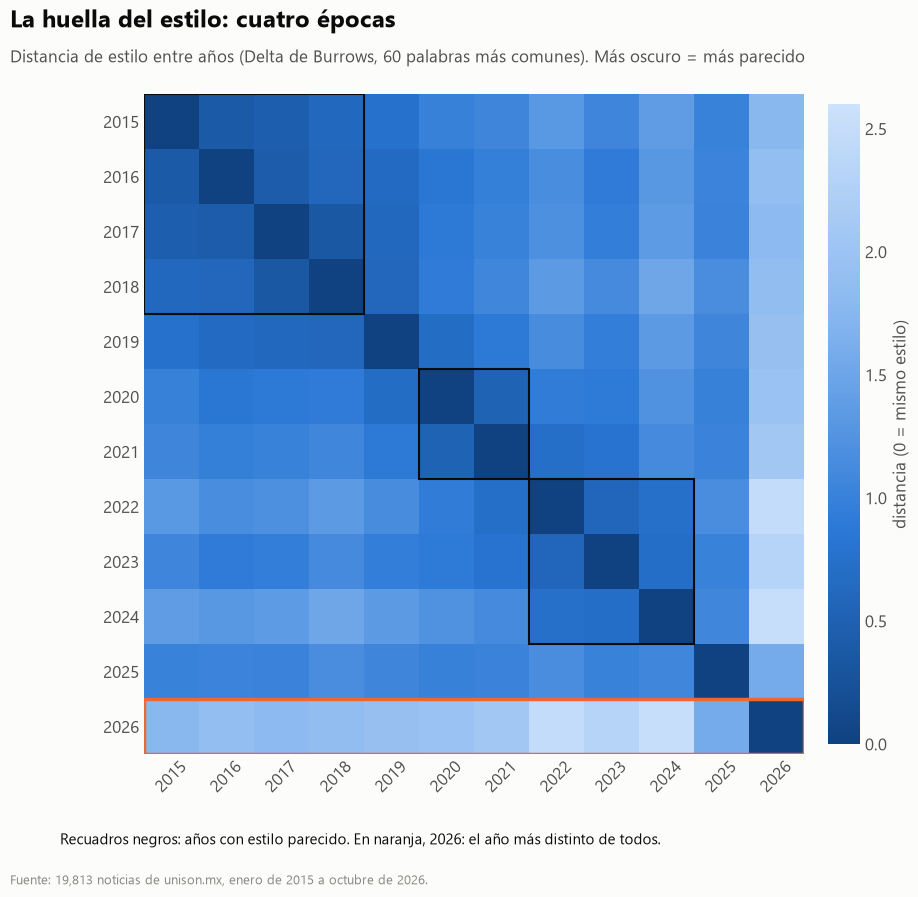

In [19]:
mapa = LinearSegmentedColormap.from_list("azules", ["#104281", "#2a78d6", "#86b6ef", "#cde2fb"])   # oscuro = parecido

fig, eje = nueva_figura("La huella del estilo: cuatro épocas",
                        "Distancia de estilo entre años (Delta de Burrows, 60 palabras más comunes). Más oscuro = más parecido",
                        ancho=10, alto=9.2)
fig.subplots_adjust(top=1 - 1.1 / 9.2, bottom=1.5 / 9.2, left=0.12, right=0.92)
imagen = eje.imshow(delta.values, cmap=mapa, vmin=0, vmax=2.6)
eje.set_xticks(range(len(anios)), anios, rotation=45)
eje.set_yticks(range(len(anios)), anios)
eje.tick_params(length=0)
for lado in eje.spines.values():
    lado.set_visible(False)

for inicio, fin in [(2015, 2018), (2020, 2021), (2022, 2024)]:          # bloques de años parecidos
    i, j = anios.index(inicio), anios.index(fin)
    eje.add_patch(Rectangle((i - 0.5, i - 0.5), j - i + 1, j - i + 1, fill=False, edgecolor=TINTA, linewidth=1.5))
fila_2026 = anios.index(2026)
eje.add_patch(Rectangle((-0.5, fila_2026 - 0.5), len(anios), 1, fill=False, edgecolor=NARANJA, linewidth=2.5))
fig.text(0.12, 0.6 / 9.2, "Recuadros negros: años con estilo parecido. En naranja, 2026: el año más distinto de todos.",
         fontsize=11, color=TINTA, ha="left")

barra = fig.colorbar(imagen, ax=eje, fraction=0.04, pad=0.03)
barra.outline.set_visible(False)
barra.ax.tick_params(length=0, labelcolor=TINTA_2)
barra.set_label("distancia (0 = mismo estilo)", color=TINTA_2)
guardar(fig, "07_huella_de_estilo.png")

¿Qué palabras pequeñas cambiaron más entre 2015–2019 y 2025–2026? (diferencia de puntajes z)

In [20]:
cambio_funcionales = (puntajes_z[[2025, 2026]].mean(axis=1) - puntajes_z[[2015, 2016, 2017, 2018, 2019]].mean(axis=1)).sort_values()

pd.DataFrame({
    "se usan menos": cambio_funcionales.head(8).index,
    "cambio (z)": cambio_funcionales.head(8).values.round(1),
    "se usan más": cambio_funcionales.tail(8).index[::-1],
    "cambio (z) ": cambio_funcionales.tail(8).values[::-1].round(1),
})

,se usan menos,cambio (z),se usan más,cambio (z)
0,esa,-2.5,como,2.4
1,otras,-2.4,con,2.2
2,le,-2.4,una,2.1
3,los,-2.4,durante,2.1
4,ese,-2.2,quienes,2.1
5,otros,-2.0,desde,2.1
6,en,-2.0,su,2.0
7,cual,-1.9,también,1.7


### 8.2 Lenguaje incluyente

*Quienes* sube y *los* baja: la huella de una forma de escribir que evita el masculino genérico. Lo medimos directamente:
qué parte de las notas de cada año usa cada forma.

In [21]:
FORMAS = {
    "«las y los»": "las y los|los y las",
    "estudiantado / alumnado / profesorado": "estudiantado|alumnado|profesorado",
    "alumno(s) / alumna(s)": r"\balumn[oa]s?\b",
}
lenguaje = pd.DataFrame({
    nombre: noticias["texto"].str.contains(patron, case=False).groupby(noticias["anio"]).mean() * 100
    for nombre, patron in FORMAS.items()
})
lenguaje.round(1)

,«las y los»,estudiantado / alumnado / profesorado,alumno(s) / alumna(s)
anio,,,
2015,0.2,1.2,39.8
2016,0.3,1.9,42.1
2017,0.5,1.0,41.1
2018,0.2,1.0,40.0
2019,0.5,1.8,39.5
2020,0.8,3.3,37.6
2021,4.1,2.1,33.3
2022,5.5,2.1,35.0
2023,5.8,3.4,35.9


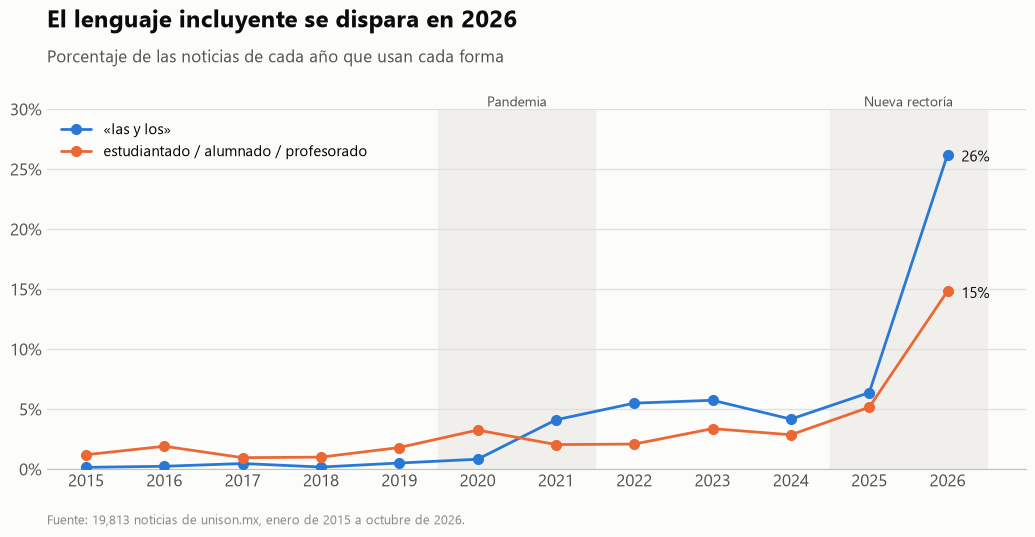

In [22]:
fig, eje = nueva_figura("El lenguaje incluyente se dispara en 2026", "Porcentaje de las noticias de cada año que usan cada forma")

for nombre, color in [("«las y los»", AZUL), ("estudiantado / alumnado / profesorado", NARANJA)]:
    serie = lenguaje[nombre]
    eje.plot(serie.index, serie.values, color=color, marker="o", markersize=7, label=nombre, zorder=3)
    eje.annotate(f"{serie.iloc[-1]:.0f}%", (serie.index[-1], serie.iloc[-1]), xytext=(10, -5),
                 textcoords="offset points", fontsize=11, color=TINTA, ha="left")

estilo_ejes(eje)
eje.set_ylim(0, 30)
eje.set_xlim(2014.5, 2027)
eje.set_xticks(anios)
eje.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "08_lenguaje_incluyente.png")

## 9. Las cifras del post

Todas las cifras que cita el post, calculadas a partir de las tablas anteriores. Si se vuelve a correr el scraper,
esta tabla dice qué números del texto hay que actualizar.

In [23]:
antes_de_2020 = voces.loc[2015:2019, "texto_entre_comillas"]
de_2022_a_2024 = voces.loc[2022:2024, "texto_entre_comillas"]
cifras = [
    ("Sección 1", "Noticias analizadas", f"{len(noticias):,}"),
    ("Sección 1", "Noticias por año, 2015–2019", f"{por_anio.loc[2015:2019].min():,} a {por_anio.loc[2015:2019].max():,}"),
    ("Sección 1", "Al 29 de octubre: 2020 contra 2019",
     f"{produccion.loc[2020, 'hasta el mismo día']} contra {produccion.loc[2019, 'hasta el mismo día']} ({caida_2020:.0f}%)"),
    ("Sección 1", "% de días con noticias en 2020", f"{equipo.loc[2020, '% de días con noticias']:.0f}%"),
    ("Sección 1", "% de notas en fin de semana, 2020–2021", f"{equipo.loc[2020:2021, '% en fin de semana'].mean():.0f}%"),
    ("Sección 1", "Noticias por año desde 2022 (años completos)", f"{por_anio.loc[2022:2025].min():,} a {por_anio.loc[2022:2025].max():,}"),
    ("Sección 1", "2026 contra 2025 a la misma fecha", f"{caida_2026:.0f}%"),
    ("Sección 1", "Firmas con 20+ notas en 2026 / % de las 3 principales",
     f"{equipo.loc[2026, 'firmas con 20+ notas']:.0f} / {equipo.loc[2026, '% de las 3 principales']:.0f}%"),
    ("Sección 2", "Palabras por noticia: 2015, 2021, 2026",
     ", ".join(f"{medianas.loc[anio, 'palabras por noticia']:.0f}" for anio in [2015, 2021, 2026])),
    ("Sección 2", "Palabras por párrafo: 2015, 2026",
     ", ".join(f"{medianas.loc[anio, 'palabras por párrafo']:.0f}" for anio in [2015, 2026])),
    ("Sección 3", "Texto entre comillas: 2015–2019 / 2022–2024",
     f"{antes_de_2020.min():.0f}–{antes_de_2020.max():.0f}% / {de_2022_a_2024.min():.0f}–{de_2022_a_2024.max():.0f}%"),
    ("Sección 3", "Titulares con cita en 2021", f"{voces.loc[2021, 'titulares_con_cita']:.0f}%"),
    ("Sección 4", "Titulares con cita: ene–abr 2025 / ago 2025 en adelante",
     f"{por_mes.loc['2025-01':'2025-04', 'titulares_con_cita'].mean():.0f}% / {por_mes.loc['2025-08':, 'titulares_con_cita'].mean():.0f}%"),
    ("Sección 4", "Texto entre comillas en 2026", f"{voces.loc[2026, 'texto_entre_comillas']:.0f}%"),
    ("Sección 4", "Titulares sin cita en 2026", f"{100 - voces.loc[2026, 'titulares_con_cita']:.0f}%"),
    ("Sección 4", "«dijo» por cada 10,000 palabras: antes → después", f"{antes['dijo']:.1f} → {despues['dijo']:.1f}"),
    ("Sección 4", "«destacó»: antes → después", f"{antes['destacó']:.1f} → {despues['destacó']:.1f}"),
    ("Sección 5", "Texto entre comillas 2024 → 2026 (A, B, C)",
     ", ".join(f"{por_periodista.loc[(p, 2024), 'texto_entre_comillas']:.0f}% → {por_periodista.loc[(p, 2026), 'texto_entre_comillas']:.0f}%"
               for p in ["Periodista A", "Periodista B", "Periodista C"])),
    ("Sección 6", "«las y los»: 2015 → 2026", f"{lenguaje.loc[2015, '«las y los»']:.1f}% → {lenguaje.loc[2026, '«las y los»']:.0f}%"),
    ("Sección 6", "estudiantado / alumnado / profesorado: 2015 → 2026",
     f"{lenguaje.loc[2015, 'estudiantado / alumnado / profesorado']:.0f}% → {lenguaje.loc[2026, 'estudiantado / alumnado / profesorado']:.0f}%"),
    ("Sección 6", "alumno(s): 2015 → 2026",
     f"{lenguaje.loc[2015, 'alumno(s) / alumna(s)']:.0f}% → {lenguaje.loc[2026, 'alumno(s) / alumna(s)']:.0f}%"),
]
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(cifras, columns=["sección del post", "cifra", "valor"])

,sección del post,cifra,valor
0,Sección 1,Noticias analizadas,"19,813"
1,Sección 1,"Noticias por año, 2015–2019","1,705 a 2,377"
2,Sección 1,Al 29 de octubre: 2020 contra 2019,697 contra 1333 (-48%)
3,Sección 1,% de días con noticias en 2020,67%
4,Sección 1,"% de notas en fin de semana, 2020–2021",7%
5,Sección 1,Noticias por año desde 2022 (años completos),"1,313 a 1,650"
6,Sección 1,2026 contra 2025 a la misma fecha,-14%
7,Sección 1,Firmas con 20+ notas en 2026 / % de las 3 principales,6 / 78%
8,Sección 2,"Palabras por noticia: 2015, 2021, 2026","371, 587, 435"
9,Sección 2,"Palabras por párrafo: 2015, 2026","47, 40"


## 10. Notas y limitaciones

- Las oraciones se cuentan por los signos de puntuación y las citas por las comillas: sirven para comparar años,
  no como valores exactos.
- Antes de 2018 las notas se firmaban con iniciales; en 2018 conviven iniciales y nombres.
- Los cambios de 2025 **coinciden en el tiempo** con el cambio de rectoría; los datos no dicen por qué ocurrieron.
- 2026 está incompleto (hasta octubre).